# What Drives the Price of a Car?
## 1. Business Understanding
A used-car dealership needs a defensible starting point for appraising vehicles and checking asking prices against comparable listings. We frame this as supervised regression, predicting advertised price in US dollars from details available at appraisal. We compare models against a fixed-price baseline and identify which attributes carry the most predictive information. The data contain asking prices. Demand, gross profit, and days to sale require dealership transaction records.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from threadpoolctl import threadpool_limits

SEED = 42
plt.rcParams["figure.dpi"] = 125
sns.set_theme(style="whitegrid", palette="colorblind")

## 2. Data Understanding
The source is the course-supplied Kaggle used-car listings extract. Each row is a listing. Inspect the schema, missingness, and extreme values before defining a practical appraisal range. Treat zero mileage or a missing title status as a prompt to check the listing.

In [2]:
raw = pd.read_csv(Path("data") / "vehicles.csv", dtype={"VIN": "string"})
audit = pd.DataFrame({"type": raw.dtypes.astype(str), "missing_pct": raw.isna().mean().mul(100)})
print(f"{len(raw):,} listings and {raw.shape[1]} fields")
display(audit.round(1).sort_values("missing_pct", ascending=False))
display(raw[["price", "year", "odometer"]].quantile([0, .01, .25, .5, .75, .99, 1]).T)

426,880 listings and 18 fields


,type,missing_pct
size,str,71.8
cylinders,str,41.6
condition,str,40.8
VIN,string,37.7
drive,str,30.6
paint_color,str,30.5
type,str,21.8
manufacturer,str,4.1
title_status,str,1.9
model,str,1.2


,0.00,0.01,0.25,0.50,0.75,0.99,1.00
price,0.0,0.0,5900.0,13950.0,26485.75,66995.0,3.736929e+09
year,1900.0,1967.0,2008.0,2013.0,2017.00,2020.0,2.022000e+03
odometer,0.0,2.0,37704.0,85548.0,133542.50,280000.0,1.000000e+07


## 3. Data Preparation
Scope the benchmark to listings from model years 1990–2022 with prices from $1,000 to $100,000. These bounds define the intended appraisal segment and exclude common placeholder prices and some specialty inventory. Treat zero and above-500,000 odometer readings as unknown. Remove identical listings once IDs are excluded. Use valid-format VINs solely to keep vehicles together across splits. For rows without a usable VIN, group exact matches on the final feature set so identical model inputs stay together. Relistings with no usable VIN and changed attributes may still cross splits.

Use model year and mileage in units a dealer can interpret. Keep state for market context and omit region to limit redundant geography. Drop size because of pervasive missingness. Use a documented unknown category for missing strings, preserve missing numerics for fold-specific processing, and retain the advertised price on the dollar scale.

In [3]:
data = raw.copy()
categorical = [
    "manufacturer", "model", "condition", "cylinders", "fuel", "title_status",
    "transmission", "drive", "type", "paint_color", "state",
]
for column in [*categorical, "region", "size"]:
    data[column] = data[column].str.strip().str.lower().replace("", np.nan)

audit_counts = {"Source listings": len(data)}
data = data.loc[data["price"].between(1_000, 100_000)].copy()
audit_counts["In price range"] = len(data)
data = data.loc[data["year"].between(1990, 2022)].copy()
audit_counts["In model-year range"] = len(data)
data["VIN"] = data["VIN"].str.strip().str.upper()
data["VIN"] = data["VIN"].where(data["VIN"].str.fullmatch(r"[A-HJ-NPR-Z0-9]{17}", na=False))
data["odometer"] = data["odometer"].where(data["odometer"].between(1, 500_000))
data = data.drop(columns="id").drop_duplicates().reset_index(drop=True)
audit_counts["After duplicate removal"] = len(data)
display(pd.Series(audit_counts, name="Listings").to_frame())

data["miles_10k"] = data["odometer"] / 10_000
numeric = ["year", "miles_10k"]
X = data[numeric + categorical].copy()
X[categorical] = X[categorical].fillna("unknown")
y = data["price"]

# Link matching features even when some rows have a VIN and some do not.
feature_key = pd.util.hash_pandas_object(X, index=False).astype(str)
feature_vins = pd.DataFrame({"key": feature_key, "VIN": data["VIN"]}).dropna()
unique_vins = feature_vins.groupby("key")["VIN"].agg(["first", "nunique"])
unambiguous_vins = unique_vins.loc[unique_vins["nunique"].eq(1), "first"]
groups = data["VIN"].fillna(feature_key.map(unambiguous_vins)).fillna("features:" + feature_key)

train_idx, test_idx = next(GroupShuffleSplit(test_size=.20, random_state=SEED).split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]
assert set(groups_train).isdisjoint(groups.iloc[test_idx])
assert X.columns.tolist() == numeric + categorical
assert len(y_train) + len(y_test) == len(data)
print(f"{len(train_idx):,} training listings | {len(test_idx):,} held-out listings")

257,202 training listings | 65,072 held-out listings


,Listings
Source listings,426880
In price range,379910
In model-year range,367097
After duplicate removal,322274


### What the training listings show
Distribution and median comparisons describe the listed inventory. Mix differences across vehicle types, years, trims, and markets can explain part of each gap.

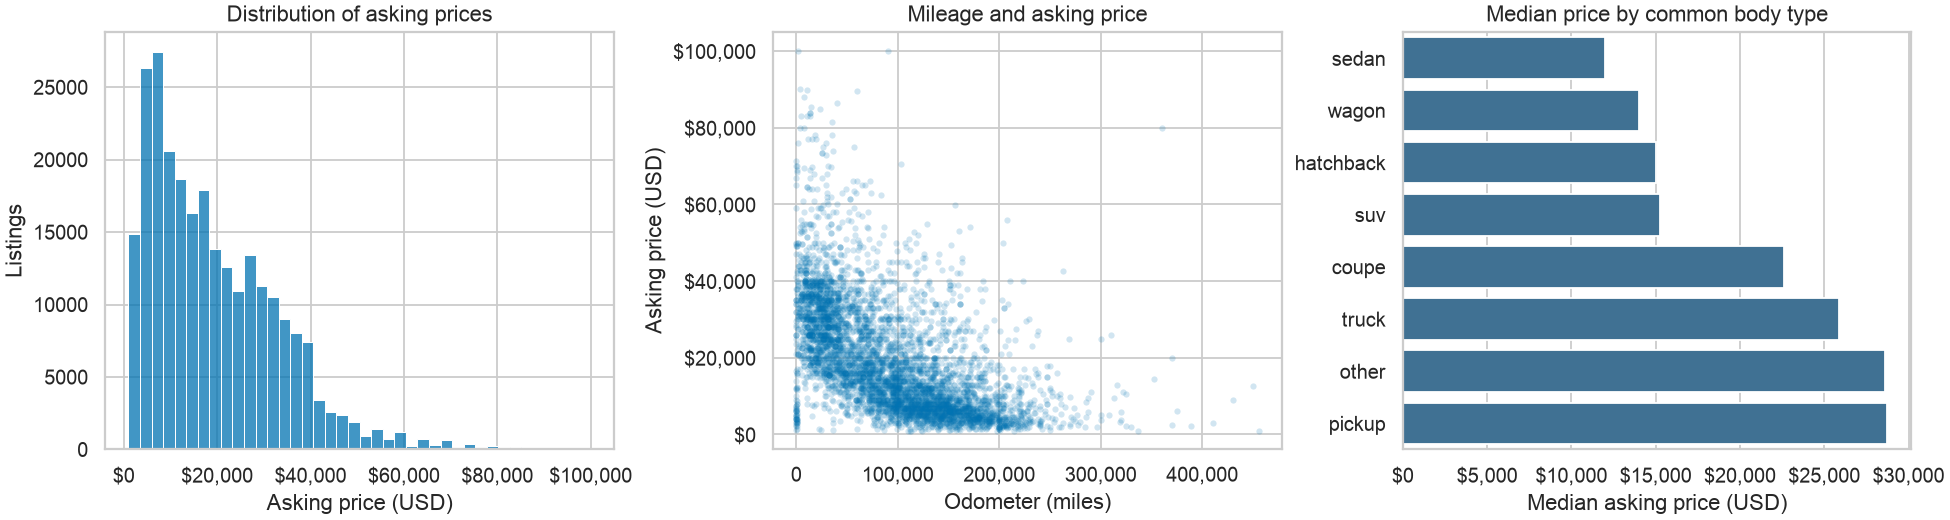

,Median asking price
type,
sedan,"$11,995"
wagon,"$13,990"
hatchback,"$14,993"
suv,"$15,250"
coupe,"$22,590"
truck,"$25,894"
other,"$28,590"
pickup,"$28,731"


In [4]:
training = data.iloc[train_idx].copy()
top_types = training["type"].value_counts().head(8).index
types = training.loc[training["type"].isin(top_types)].groupby("type")["price"].median().sort_values()
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
sns.histplot(training["price"], bins=40, ax=axes[0])
axes[0].set(title="Distribution of asking prices", xlabel="Asking price (USD)", ylabel="Listings")
sns.scatterplot(
    data=training.sample(5000, random_state=SEED), x="odometer", y="price",
    alpha=.18, s=12, linewidth=0, ax=axes[1],
)
axes[1].set(title="Mileage and asking price", xlabel="Odometer (miles)", ylabel="Asking price (USD)")
sns.barplot(x=types.values, y=types.index, ax=axes[2], color="#3274a1")
axes[2].set(title="Median price by common body type", xlabel="Median asking price (USD)", ylabel="")
for axis in (axes[0], axes[2]):
    axis.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
axes[1].yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
axes[1].xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.show()
display(types.map("${:,.0f}".format).rename("Median asking price").to_frame())

### Model year and title in the training inventory
The year curve shows how median asking prices vary across model years. Title comparisons are shown separately for two mileage bands to reduce differences in mileage mix. Each comparison can still reflect differences in trim, condition, model year, and other recorded or unrecorded attributes.

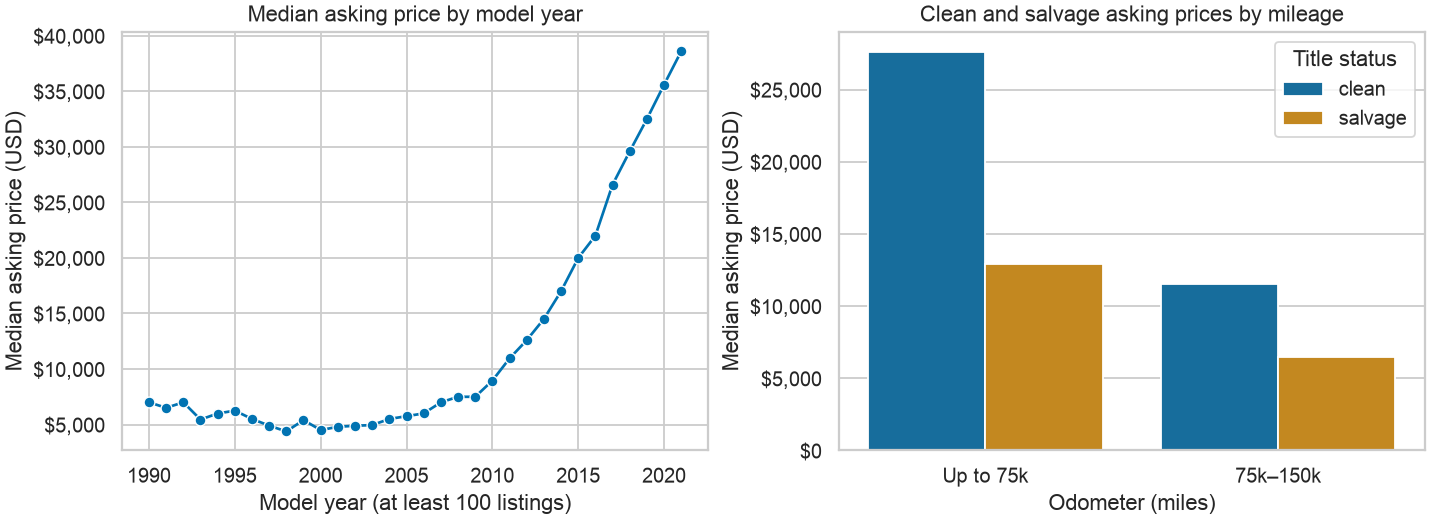

,Mileage band,title_status,median,listings
0,Up to 75k,clean,27590.0,107002
1,Up to 75k,salvage,12900.0,1011
2,75k–150k,clean,11500.0,88498
3,75k–150k,salvage,6500.0,1002


In [5]:
year_summary = training.groupby("year")["price"].agg(["median", "size"])
year_summary = year_summary.loc[year_summary["size"].ge(100)]
title_sample = training.loc[
    training["title_status"].isin(["clean", "salvage"]) & training["odometer"].between(1, 150_000)
].copy()
title_sample["Mileage band"] = pd.cut(
    title_sample["odometer"], [0, 75_000, 150_000], labels=["Up to 75k", "75k–150k"]
)
title_summary = title_sample.groupby(
    ["Mileage band", "title_status"], observed=True
)["price"].agg(median="median", listings="size").reset_index()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
sns.lineplot(data=year_summary, x=year_summary.index, y="median", marker="o", ax=axes[0])
axes[0].set(title="Median asking price by model year",
            xlabel="Model year (at least 100 listings)", ylabel="Median asking price (USD)")
sns.barplot(data=title_summary, x="Mileage band", y="median", hue="title_status",
            hue_order=["clean", "salvage"], ax=axes[1])
axes[1].set(title="Clean and salvage asking prices by mileage",
            xlabel="Odometer (miles)", ylabel="Median asking price (USD)")
axes[1].legend(title="Title status")
for axis in axes:
    axis.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
plt.show()
display(title_summary.round({"median": 0}))

## 4. Modeling
Compare a median-price baseline, ordinary least squares, Ridge, and histogram gradient boosting. Linear models use median imputation with missingness flags, scaled numerics, and sparse one-hot categories. Rare levels share a bucket. Boosting uses native missing values for numerics and native categorical splits with limited category counts. Every learned transformation is fitted within its training fold.

All candidates use the same three group-disjoint folds. Grid search tunes Ridge regularization and boosting iteration and leaf counts. Select on mean validation MAE because it measures the typical dollar size of a pricing miss and is less sensitive to rare large misses than RMSE. Also report RMSE to expose large misses and R² to summarize variation explained. Evaluate the fitted models on the held-out partition only after selection.

In [6]:
linear_preprocess = ColumnTransformer(
    [
        ("numeric", Pipeline([
            ("impute", SimpleImputer(strategy="median", add_indicator=True)),
            ("scale", StandardScaler()),
        ]), numeric),
        ("categorical", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=35), categorical),
    ],
    sparse_threshold=1.0,
)
tree_preprocess = ColumnTransformer([
    ("numeric", "passthrough", numeric),
    ("categorical", OrdinalEncoder(
        handle_unknown="use_encoded_value", unknown_value=np.nan, max_categories=127,
    ), categorical),
])
models = {
    "Median baseline": (DummyRegressor(strategy="median"), {}),
    "Least squares": (Pipeline([
        ("prep", linear_preprocess), ("regressor", LinearRegression(tol=1e-4)),
    ]), {}),
    "Ridge": (Pipeline([
        ("prep", linear_preprocess), ("regressor", Ridge(solver="lsqr")),
    ]), {"regressor__alpha": [1, 10, 100]}),
    "Gradient boosting": (Pipeline([
        ("prep", tree_preprocess),
        ("regressor", HistGradientBoostingRegressor(
            categorical_features=[False] * len(numeric) + [True] * len(categorical),
            random_state=SEED, early_stopping=False, min_samples_leaf=35,
        )),
    ]), {"regressor__max_leaf_nodes": [31, 63], "regressor__max_iter": [150, 300]}),
}
folds = list(GroupKFold(n_splits=3).split(X_train, y_train, groups_train))
for fit_rows, validation_rows in folds:
    assert set(groups_train.iloc[fit_rows]).isdisjoint(groups_train.iloc[validation_rows])

searches = {}
grid_rows = []
with threadpool_limits(limits=4):
    for name, (model, grid) in models.items():
        search = GridSearchCV(
            model, grid, cv=folds, refit="mae", error_score="raise",
            scoring={"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"},
        )
        search.fit(X_train, y_train)
        searches[name] = search
        results = pd.DataFrame(search.cv_results_)
        grid_rows.extend({
            "Model": name, "Parameters": params,
            "CV MAE": -mae, "CV MAE SD": std,
        } for params, mae, std in zip(
            results["params"], results["mean_test_mae"], results["std_test_mae"]
        ))
grid_results = pd.DataFrame(grid_rows)
grid_display = grid_results.copy()
grid_display["Parameters"] = grid_display["Parameters"].map(
    lambda params: ", ".join(f"{key.split('__')[-1]}={value}" for key, value in params.items()) or "Default"
)
with pd.option_context("display.max_colwidth", None, "display.width", 120):
    display(grid_display.round({"CV MAE": 0, "CV MAE SD": 0}))
winner = max(searches, key=lambda name: searches[name].best_score_)
print(f"Selected by cross-validation: {winner}")
print(f"Selected settings: {searches[winner].best_params_}")

Selected by cross-validation: Gradient boosting
Selected settings: {'regressor__max_iter': 300, 'regressor__max_leaf_nodes': 63}


,Model,Parameters,CV MAE,CV MAE SD
0,Median baseline,Default,11131.0,36.0
1,Least squares,Default,4856.0,44.0
2,Ridge,alpha=1,4854.0,44.0
3,Ridge,alpha=10,4857.0,40.0
4,Ridge,alpha=100,5015.0,23.0
5,Gradient boosting,"max_iter=150, max_leaf_nodes=31",3437.0,45.0
6,Gradient boosting,"max_iter=150, max_leaf_nodes=63",3326.0,47.0
7,Gradient boosting,"max_iter=300, max_leaf_nodes=31",3338.0,44.0
8,Gradient boosting,"max_iter=300, max_leaf_nodes=63",3265.0,46.0


## 5. Evaluation
Compare holdout MAE, RMSE, and R². Positive signed errors mean the model quotes above asking prices. Measure absolute errors across price bands to see when a desk appraisal needs more scrutiny.

In [7]:
predictions = {}
rows = []
with threadpool_limits(limits=4):
    for name, search in searches.items():
        predicted = search.predict(X_test)
        predictions[name] = predicted
        rows.append({
            "Model": name, "CV MAE": -search.best_score_,
            "Holdout MAE": mean_absolute_error(y_test, predicted),
            "Holdout RMSE": root_mean_squared_error(y_test, predicted),
            "Holdout R²": r2_score(y_test, predicted),
        })
scores = pd.DataFrame(rows).set_index("Model").sort_values("CV MAE")
display(scores.round({"CV MAE": 0, "Holdout MAE": 0, "Holdout RMSE": 0, "Holdout R²": 3}))

errors = pd.DataFrame({"actual": y_test, "predicted": predictions[winner]}, index=y_test.index)
errors["signed"] = errors["predicted"] - errors["actual"]
errors["absolute"] = errors["signed"].abs()
assert np.isclose(errors["absolute"].mean(), scores.loc[winner, "Holdout MAE"])
assert np.isclose(np.sqrt(errors["signed"].pow(2).mean()), scores.loc[winner, "Holdout RMSE"])
price_band = pd.cut(errors["actual"], [0, 10_000, 25_000, 50_000, np.inf],
                    labels=["Up to $10k", "$10k–$25k", "$25k–$50k", "Above $50k"])
band_errors = errors.groupby(price_band, observed=True).agg(
    listings=("actual", "size"), mae=("absolute", "mean"), bias=("signed", "mean")
)
display(band_errors.round(0))
print(f"90% of holdout absolute errors were at or below ${errors['absolute'].quantile(.90):,.0f}.")

90% of holdout absolute errors were at or below $7,318.


,CV MAE,Holdout MAE,Holdout RMSE,Holdout R²
Model,,,,
Gradient boosting,3265.0,3249.0,5330.0,0.864
Ridge,4854.0,4794.0,7268.0,0.747
Least squares,4856.0,4796.0,7270.0,0.747
Median baseline,11131.0,11293.0,14920.0,-0.065


,listings,mae,bias
actual,,,
Up to $10k,21556,2018.0,1254.0
$10k–$25k,23387,2864.0,443.0
$25k–$50k,17972,4234.0,-1291.0
Above $50k,2157,11514.0,-9435.0


### Which vehicle attributes carry information?
Shuffle one raw field at a time on the same held-out sample and measure the increase in MAE for the winning model. A higher increase means the fitted model relied more on that field. This can disrupt realistic combinations, and correlated attributes can share or mask importance. The bars report variability across shuffles, not confidence intervals.

Use Ridge for direction and dollar scale. Divide the fitted year and mileage coefficients by the training standard deviations to return to original units. Compare title levels by subtracting the two one-hot coefficients so the difference has a clear reference. These are adjusted associations conditional on recorded fields and can reflect unobserved differences in inventory. They are neither causal effects nor universal price adjustments.

,Adjusted price difference (USD)
One model year newer,1074.0
"10,000 additional miles",-658.0
Salvage title vs clean,-5282.0


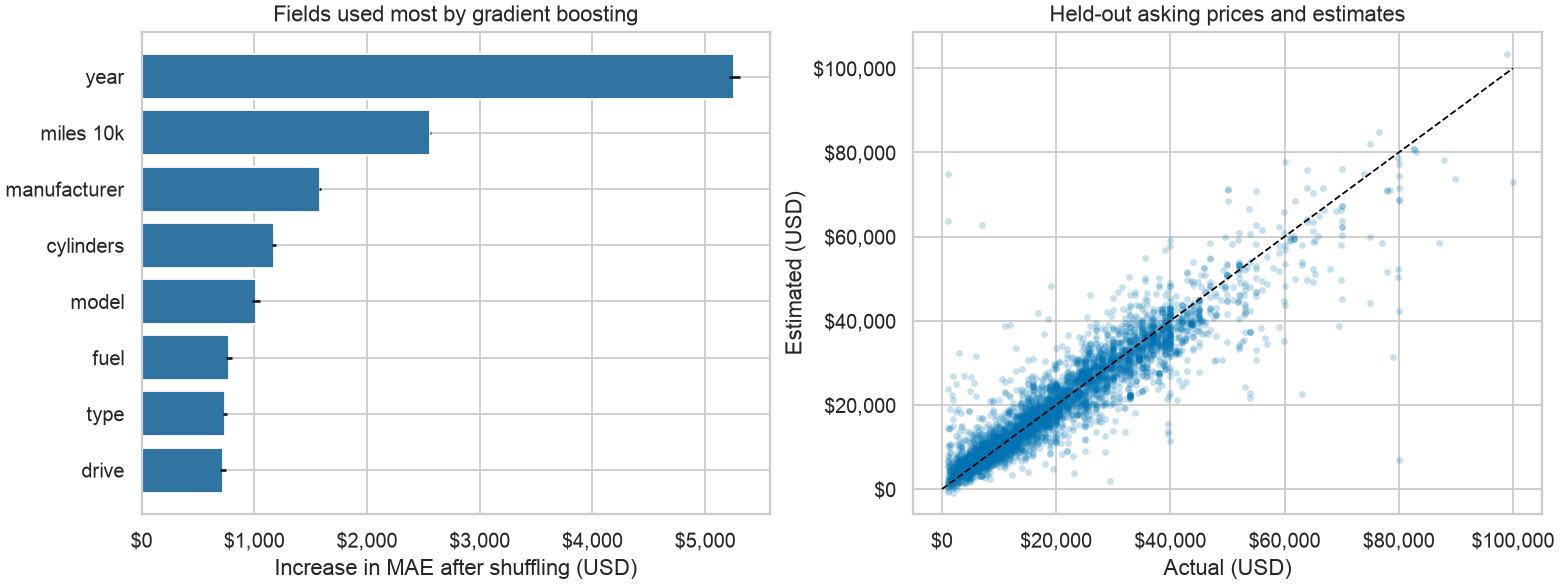

In [8]:
sample = X_test.sample(6000, random_state=SEED)
with threadpool_limits(limits=4):
    perm = permutation_importance(
        searches[winner], sample, y_test.loc[sample.index],
        scoring="neg_mean_absolute_error", n_repeats=3, random_state=SEED,
    )
importance = pd.DataFrame({
    "MAE increase": perm.importances_mean, "SD": perm.importances_std,
}, index=X.columns).sort_values("MAE increase", ascending=False)

ridge = searches["Ridge"].best_estimator_
prep = ridge.named_steps["prep"]
scaler = prep.named_transformers_["numeric"].named_steps["scale"]
coefficients = pd.Series(ridge.named_steps["regressor"].coef_, index=prep.get_feature_names_out())
effects = pd.Series({
    "One model year newer": coefficients["numeric__year"] / scaler.scale_[0],
    "10,000 additional miles": coefficients["numeric__miles_10k"] / scaler.scale_[1],
    "Salvage title vs clean": coefficients["categorical__title_status_salvage"]
                              - coefficients["categorical__title_status_clean"],
}, name="Adjusted price difference (USD)")
display(effects.round(0).to_frame())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
shown = importance.head(8).sort_values("MAE increase")
axes[0].barh(shown.index.str.replace("_", " "), shown["MAE increase"], xerr=shown["SD"], color="#3274a1")
axes[0].set(title=f"Fields used most by {winner.lower()}", xlabel="Increase in MAE after shuffling (USD)")
plot_rows = errors.sample(5000, random_state=SEED)
sns.scatterplot(data=plot_rows, x="actual", y="predicted", alpha=.22, s=14, linewidth=0, ax=axes[1])
axes[1].plot([0, 100_000], [0, 100_000], color="black", linestyle="--", linewidth=1)
axes[1].set(title="Held-out asking prices and estimates", xlabel="Actual (USD)", ylabel="Estimated (USD)")
for axis in axes:
    axis.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
axes[1].yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
plt.show()

### Where pricing misses become more expensive
The left panel compares the dollar size of errors across price bands. The right panel shows their direction. A small signed error can hide large misses in both directions, so read the panels together. Bands use observed asking prices and summarize the holdout.

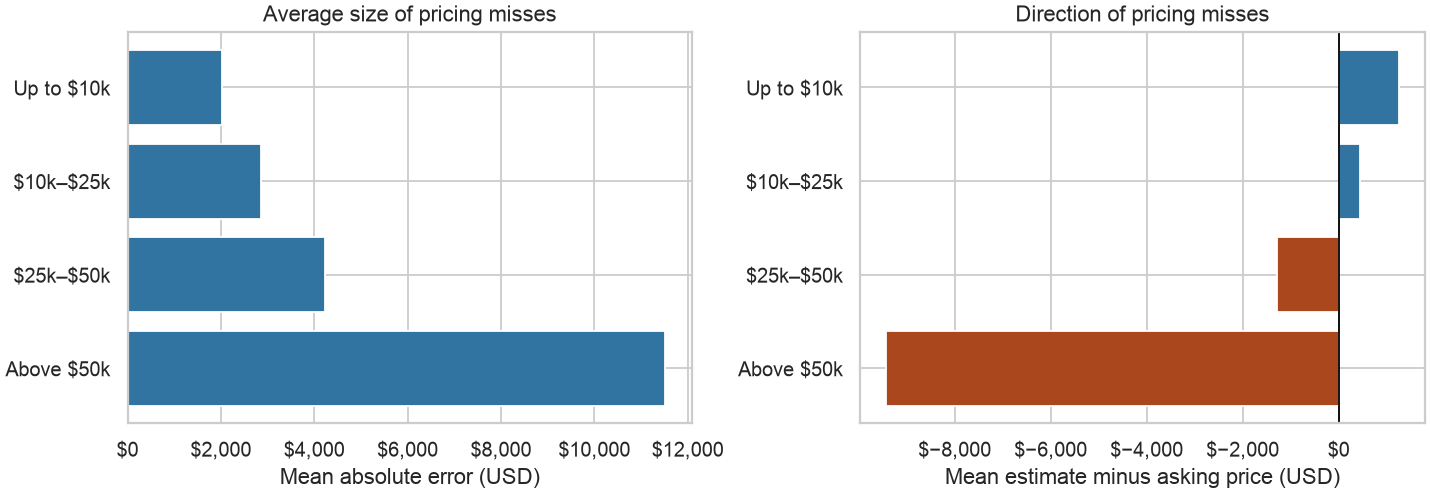

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
band_labels = ["Up to $10k", "$10k–$25k", "$25k–$50k", "Above $50k"]
order = np.arange(len(band_errors))
axes[0].barh(order, band_errors["mae"], color="#3274a1")
axes[1].barh(order, band_errors["bias"], color=["#3274a1" if v >= 0 else "#ab471c" for v in band_errors["bias"]])
axes[0].set(title="Average size of pricing misses", xlabel="Mean absolute error (USD)")
axes[1].set(title="Direction of pricing misses",
            xlabel="Mean estimate minus asking price (USD)")
axes[1].axvline(0, color="black", linewidth=1)
for axis in axes:
    axis.set_yticks(order, band_labels, parse_math=False)
    axis.invert_yaxis()
    axis.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
plt.show()

### Findings for the appraisal desk

- **Start with model year, mileage and comparable vehicle details.** Year and mileage increased the winning model's error by $5,259 and $2,561 when shuffled. Make, cylinder count, and model were the next strongest signals. The adjusted Ridge estimates associate a newer year with $1,074 more and an extra 10,000 miles with $658 less. Use these relationships to narrow the comparable set.
- **Verify title status.** Ridge estimates about $5,282 less for salvage than clean title at the same recorded attributes. An inspection and like-title comparables matter, especially when repairs and accident history are missing.
- **Escalate high-dollar and unusual appraisals.** Gradient boosting reduced holdout MAE from $11,293 to $3,249. RMSE was $5,330, reflecting larger misses. Above $50,000, the average miss was $11,514 and the average estimate was $9,435 below the asking price.
- **Read the body-type comparison in context.** Pickups had a median asking price of $28,731 versus $11,995 for sedans in training. The samples can differ in age, mileage, engine and trim. Higher asking prices alone give dealers little basis for forecasting profit or turnover.

## 6. Deployment
Use the benchmark during a shadow trial alongside appraisers. Enter verified vehicle identity, odometer, title, condition, and equipment, then use local comparables and inspection results before setting an asking price or making an acquisition offer. Log manual overrides and review errors by segment. Collect sold prices, reconditioning cost, gross margin, and days to sale before using the tool to alter buying targets. Validate on recent and future dealership inventory before operational use. See the [dealer findings report](dealer_findings.pdf).